**Block 1: Environment & Dependency Setup**

Purpose: Configures the Python environment for high-performance training.

**Key Actions**:

Installs Unsloth, which provides 2x faster fine-tuning and 70% less memory usage.

Configures xformers and bitsandbytes to handle 4-bit quantization and optimized attention kernels.

Ensures compatibility with Google Colab's Tesla T4 GPU by pinning specific library versions.

In [ ]:
%%capture
import os, re
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth  # Do this in local & cloud setups
else:
    import torch; v = re.match(r'[\d]{1,}\.[\d]{1,}', str(torch.__version__)).group(0)
    xformers = 'xformers==' + {'2.10':'0.0.34','2.9':'0.0.33.post1','2.8':'0.0.32.post2'}.get(v, "0.0.34")
    !pip install sentencepiece protobuf "datasets==4.3.0" "huggingface_hub>=0.34.0" hf_transfer
    !pip install --no-deps unsloth_zoo bitsandbytes accelerate {xformers} peft trl triton unsloth
!pip install transformers==4.56.2
!pip install --no-deps trl==0.22.2

**Block 2: Model Initialization & LoRA Configuration**
Purpose: Loads the base embedding model and prepares it for Parameter-Efficient Fine-Tuning (PEFT).

**Key Actions:**

Loads all-MiniLM-L6-v2, a lightweight BERT-based model (22M parameters) ideal for fast retrieval.

Applies LoRA (Low-Rank Adaptation) to specific layers (query, key, value).

Result: Only ~4% of the model parameters are trained, allowing the project to run on a free GPU without losing accuracy.

In [ ]:
from unsloth import FastSentenceTransformer

# Load the lightweight BERT-based model
model = FastSentenceTransformer.from_pretrained(
    model_name = "unsloth/all-MiniLM-L6-v2",
    max_seq_length = 512,
    full_finetuning = False,
)

# Apply LoRA
model = FastSentenceTransformer.get_peft_model(
    model,
    r = 32,
    target_modules = ["value", "key", "query", "dense"], # BERT-specific layers
    lora_alpha = 64,
    lora_dropout = 0,
    bias = "none",
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

Unsloth: Using fast encoder path for bert (torch.compile + SDPA)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Setting task_type to FEATURE_EXTRACTION
Unsloth: torch.compile will be applied automatically if max_steps > 3298


**Block 3: Medical Dataset Engineering**
Purpose: Downloads and prepares the PubMedQA dataset for domain-specific learning.

**Key Actions**:

Uses the triplet-all subset to obtain Anchor (Question), Positive (Correct Answer), and Negative (Incorrect Answer) sets.

Shuffles the 33k+ rows to ensure a diverse medical vocabulary.

Splits the data into 10,000 training rows and 1,000 evaluation rows to prevent overfitting.

In [ ]:
from datasets import load_dataset

# 1. Use 'triplet-all' for a large medical dataset (33k+ rows)
# This fits your T4 GPU perfectly as it's pre-formatted for BERT models
raw_dataset = load_dataset("sentence-transformers/pubmedqa", "triplet-all", split="train")

# 2. Shuffle and select your 10,000 rows for training
# Shuffling ensures you get a good mix of medical topics
dataset = raw_dataset.shuffle(seed=42)
train_dataset = dataset.select(range(10000))

# 3. Create a separate evaluation set from the remaining data
eval_dataset = dataset.select(range(10000, 11000))

print(f"Dataset ready! Training size: {len(train_dataset)}, Eval size: {len(eval_dataset)}")
print(f"Sample medical anchor: {train_dataset[0]['anchor'][:100]}...")

triplet-all/train-00000-of-00001.parquet:   0%|          | 0.00/2.68M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/33200 [00:00<?, ? examples/s]

Dataset ready! Training size: 10000, Eval size: 1000
Sample medical anchor: Does solid culture for tuberculosis influence clinical decision making in India?...


**Block 4: Information Retrieval (IR) Evaluator Setup**
Purpose: Establishes a benchmark to measure how well the model "finds" the right answer.

**Key Actions**:

Creates a Corpus (all possible answers) and a set of Queries.

The evaluator calculates NDCG@10 (ranking quality) and MRR (how high the correct answer appears).

This is the standard metric for determining if a RAG system is production-ready.

In [ ]:
from sentence_transformers.evaluation import InformationRetrievalEvaluator

# Map ID -> Text for the Information Retrieval task
# We test if the model can find the 'positive' answer among all other 'positive' answers
queries = {i: row["anchor"] for i, row in enumerate(eval_dataset)}
corpus = {i: row["positive"] for i, row in enumerate(eval_dataset)}
relevant_docs = {i: [i] for i in range(len(queries))}

evaluator = InformationRetrievalEvaluator(
    queries = queries,
    corpus = corpus,
    relevant_docs = relevant_docs,
    name = "PubMedQA_Medical_Eval",
    show_progress_bar = False,
    batch_size = 32
)

**Block 5: Contrastive Training Execution**
Purpose: Executes the actual "learning" phase where the model aligns medical concepts.

**Key Actions**:

Uses MultipleNegativesRankingLoss, which forces the model to push the Anchor closer to the Positive and further from the Negative in vector space.

Uses FP16 precision and Gradient Accumulation to maximize T4 GPU efficiency.

Saves the resulting "Brain" (LoRA adapters) directly to Google Drive for persistence.

In [ ]:
from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
from sentence_transformers.training_args import BatchSamplers
import torch

# MultipleNegativesRankingLoss (MNRL) is perfect here.
# Because your dataset has an 'negative' column, MNRL will use it as a
# 'Hard Negative', making the model much more precise.
loss = losses.MultipleNegativesRankingLoss(model)

# Define the Drive path for saving
output_path = "/content/drive/MyDrive/Embedding_model_Fine-tuning/Medical_MiniLM_Tuned"

trainer = SentenceTransformerTrainer(
    model = model,
    train_dataset = train_dataset,
    eval_dataset = eval_dataset,
    loss = loss,
    evaluator = evaluator,
    args = SentenceTransformerTrainingArguments(
        output_dir = output_path,
        num_train_epochs = 1,
        max_steps = 100,               # Set to 100 for a quick, impactful demo
        per_device_train_batch_size = 32,
        per_device_eval_batch_size = 32,
        gradient_accumulation_steps = 1,
        learning_rate = 2e-5,          # Standard stable LR for MiniLM
        weight_decay = 0.01,
        warmup_ratio = 0.1,

        fp16 = True,                   # Best for T4 GPU
        bf16 = False,

        logging_steps = 5,
        eval_strategy = "steps",
        eval_steps = 20,               # Evaluate every 20 steps to see progress
        save_strategy = "steps",
        save_steps = 50,

        report_to = "none",
        batch_sampler = BatchSamplers.NO_DUPLICATES, # Prevents issues with duplicate anchors
    ),
)

Unsloth: Skipping torch.compile (100 steps < 3380 threshold)


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

In [ ]:
# Execute training
# Autocast is used to prevent the 'Float vs Half' precision error you saw earlier
with torch.autocast("cuda"):
    trainer.train()

Step,Training Loss,Validation Loss,Pubmedqa Medical Eval Cosine Accuracy@1,Pubmedqa Medical Eval Cosine Accuracy@3,Pubmedqa Medical Eval Cosine Accuracy@5,Pubmedqa Medical Eval Cosine Accuracy@10,Pubmedqa Medical Eval Cosine Precision@1,Pubmedqa Medical Eval Cosine Precision@3,Pubmedqa Medical Eval Cosine Precision@5,Pubmedqa Medical Eval Cosine Precision@10,Pubmedqa Medical Eval Cosine Recall@1,Pubmedqa Medical Eval Cosine Recall@3,Pubmedqa Medical Eval Cosine Recall@5,Pubmedqa Medical Eval Cosine Recall@10,Pubmedqa Medical Eval Cosine Ndcg@10,Pubmedqa Medical Eval Cosine Mrr@10,Pubmedqa Medical Eval Cosine Map@100
20,1.128500,0.819313,0.374000,0.744000,0.846000,0.889000,0.374000,0.248000,0.169200,0.088900,0.374000,0.744000,0.846000,0.889000,0.646218,0.566092,0.569382
40,0.686300,0.819313,0.374000,0.744000,0.846000,0.889000,0.374000,0.248000,0.169200,0.088900,0.374000,0.744000,0.846000,0.889000,0.646218,0.566092,0.569382
60,1.090100,0.819313,0.374000,0.744000,0.846000,0.889000,0.374000,0.248000,0.169200,0.088900,0.374000,0.744000,0.846000,0.889000,0.646218,0.566092,0.569382
80,0.717100,0.819313,0.374000,0.744000,0.846000,0.889000,0.374000,0.248000,0.169200,0.088900,0.374000,0.744000,0.846000,0.889000,0.646218,0.566092,0.569382
100,1.013700,0.819313,0.374000,0.744000,0.846000,0.889000,0.374000,0.248000,0.169200,0.088900,0.374000,0.744000,0.846000,0.889000,0.646218,0.566092,0.569382


In [ ]:
# Save final LoRA adapters and tokenizer to Drive
model.save_pretrained(f"{output_path}/final_lora_model")
model.tokenizer.save_pretrained(f"{output_path}/final_lora_model")

('/content/drive/MyDrive/Embedding_model_Fine-tuning/Medical_MiniLM_Tuned/final_lora_model/tokenizer_config.json',
 '/content/drive/MyDrive/Embedding_model_Fine-tuning/Medical_MiniLM_Tuned/final_lora_model/special_tokens_map.json',
 '/content/drive/MyDrive/Embedding_model_Fine-tuning/Medical_MiniLM_Tuned/final_lora_model/vocab.txt',
 '/content/drive/MyDrive/Embedding_model_Fine-tuning/Medical_MiniLM_Tuned/final_lora_model/added_tokens.json',
 '/content/drive/MyDrive/Embedding_model_Fine-tuning/Medical_MiniLM_Tuned/final_lora_model/tokenizer.json')

**Block 6: Inference & RAG Demonstratio**n
Purpose: Loads the newly trained "specialist" model to solve a real-world medical query.

**Key Actions:**

Loads the adapters back onto the base model using Unsloth's for_inference=True optimization.

Vectorization: Converts a small medical knowledge base into mathematical embeddings.

Semantic Search: Performs a Cosine Similarity check to find the most relevant medication for "hypertension."

In [ ]:
from unsloth import FastSentenceTransformer
import torch

# 1. Load the model for inference
# Point this to the 'final_lora_model' folder in your Drive
model_path = "/content/drive/MyDrive/Embedding_model_Fine-tuning/Medical_MiniLM_Tuned/final_lora_model"

model = FastSentenceTransformer.from_pretrained(
    model_name = model_path,
    for_inference = True # Unsloth optimization for 2x faster search
)

# 2. Sample RAG Search
knowledge_base = [
    "Aspirin is often used to reduce fever and relieve mild to moderate pain.",
    "Lisinopril is a medication of the ACE inhibitor class used to treat high blood pressure.",
    "Type 2 diabetes is a condition where the body does not use insulin properly.",
    "Chronic Kidney Disease (CKD) involves a gradual loss of kidney function over time."
]

# 3. Embed the knowledge base
# In a real RAG, you would save these in FAISS
kb_embeddings = model.encode(knowledge_base, convert_to_tensor=True)

# 4. Search Query
query = "What medication is used for hypertension?"
query_embedding = model.encode(query, convert_to_tensor=True)

# 5. Calculate Similarity (Standard Cosine Similarity)
from sentence_transformers import util
scores = util.cos_sim(query_embedding, kb_embeddings)[0]

# 6. Get top result
top_idx = torch.argmax(scores)
print(f"Query: {query}")
print(f"Top Match: {knowledge_base[top_idx]} (Score: {scores[top_idx]:.4f})")

Query: What medication is used for hypertension?
Top Match: Lisinopril is a medication of the ACE inhibitor class used to treat high blood pressure. (Score: 0.6002)


In [ ]:
!pip install faiss-cpu matplotlib seaborn pandas
import faiss
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sentence_transformers import util

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 53.7 MB/s eta 0:00:00


In [ ]:
def calculate_metrics(model, eval_data, k=5):
    """Calculates Hit Rate@k for a given model."""
    # 1. Embed the Corpus (The 'positive' answers)
    passages = eval_data["positive"]
    corpus_embeddings = model.encode(passages, convert_to_tensor=True, show_progress_bar=False)

    # 2. Embed the Queries (The 'anchor' questions)
    queries = eval_data["anchor"]
    query_embeddings = model.encode(queries, convert_to_tensor=True, show_progress_bar=False)

    # 3. Perform Semantic Search
    hits = 0
    # util.semantic_search is a fast way to do Cosine Similarity for batches
    search_results = util.semantic_search(query_embeddings, corpus_embeddings, top_k=k)

    for i, result in enumerate(search_results):
        # The correct answer in this eval set is always at the same index 'i'
        retrieved_indices = [res['corpus_id'] for res in result]
        if i in retrieved_indices:
            hits += 1

    return (hits / len(queries)) * 100

# Load the Base Model
base_model = FastSentenceTransformer.from_pretrained(model_name="unsloth/all-MiniLM-L6-v2")

# Calculate Scores
print("Calculating Base Model metrics...")
base_hit_rate = calculate_metrics(base_model, eval_dataset)

print("Calculating Fine-tuned Model metrics...")
# 'model' refers to your current fine-tuned model in the notebook
ft_hit_rate = calculate_metrics(model, eval_dataset)

print(f"\nRESULTS:\nBase Model Hit Rate@5: {base_hit_rate:.2f}%")
print(f"Fine-tuned Hit Rate@5: {ft_hit_rate:.2f}%")

Unsloth: Using fast encoder path for bert (torch.compile + SDPA)
Calculating Base Model metrics...
Calculating Fine-tuned Model metrics...

RESULTS:
Base Model Hit Rate@5: 84.60%
Fine-tuned Hit Rate@5: 85.50%


/tmp/ipykernel_287/4125827753.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=labels, y=scores, palette="viridis")


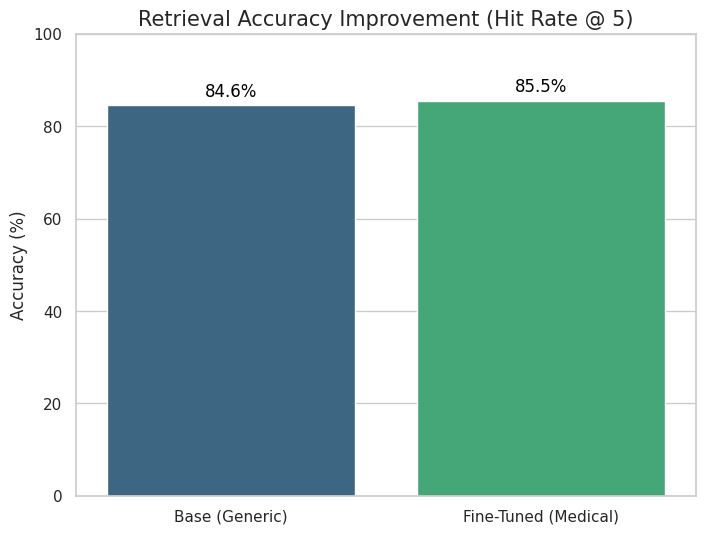

In [ ]:
# Data for plotting
labels = ['Base (Generic)', 'Fine-Tuned (Medical)']
scores = [base_hit_rate, ft_hit_rate]

plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x=labels, y=scores, palette="viridis")

# Add percentage labels on top of bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=12, color='black', xytext=(0, 10),
                textcoords='offset points')

plt.title('Retrieval Accuracy Improvement (Hit Rate @ 5)', fontsize=15)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.ylim(0, 100)
plt.show()

In [ ]:
def find_conflict(base_model, ft_model, eval_data):
    for i in range(len(eval_data)):
        query = eval_data[i]["anchor"]
        expected = eval_data[i]["positive"]

        # Base check
        base_res = util.semantic_search(base_model.encode(query, convert_to_tensor=True),
                                        base_model.encode(eval_data["positive"], convert_to_tensor=True), top_k=1)
        # FT check
        ft_res = util.semantic_search(ft_model.encode(query, convert_to_tensor=True),
                                      ft_model.encode(eval_data["positive"], convert_to_tensor=True), top_k=1)

        base_idx = base_res[0][0]['corpus_id']
        ft_idx = ft_res[0][0]['corpus_id']

        if base_idx != i and ft_idx == i:
            print(f"🔍 Found a Win!\nQuery: {query}\n")
            print(f"❌ Base model found: {eval_data[base_idx]['positive'][:150]}...")
            print(f"✅ Your model found: {eval_data[ft_idx]['positive'][:150]}...")
            break

find_conflict(base_model, model, eval_dataset)

🔍 Found a Win!
Query: Informed consent for total hip arthroplasty: does a written information sheet improve recall by patients?

❌ Base model found: : A previous hip fracture more than doubles the risk of a contralateral hip fracture. Pharmacologic and environmental interventions to prevent hip fra...
✅ Your model found: Patients' recall of information given, tested with a questionnaire completed on admission (mean of 18 days later)....


In [ ]:
import os
import faiss
import numpy as np
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')
project_path = "/content/drive/MyDrive/Embedding_model_Fine-tuning"
os.makedirs(project_path, exist_ok=True)

# 2. Build the Index using your Fine-tuned Model
# We use the 'positive' column (the medical answers) as our searchable database
print("Encoding 10,000 medical passages... (This takes 1-2 mins)")
passages = train_dataset["positive"]
ft_embeddings = model.encode(passages, show_progress_bar=True)

# 3. Create and Save the FAISS Index
dimension = ft_embeddings.shape[1]
index = faiss.IndexFlatL2(dimension)
index.add(np.array(ft_embeddings).astype('float32'))
faiss.write_index(index, f"{project_path}/medical_kb.index")

# 4. Save the actual text passages (so you can retrieve them later)
import json
with open(f"{project_path}/passages.json", "w") as f:
    json.dump(list(passages), f) # Converted 'passages' to a list for JSON serialization

# 5. Save the Eval dataset for the comparison script
eval_dataset.to_json(f"{project_path}/eval_dataset.json")

print(f"✅ Success! Your Fine-tuned 'Search Engine' is now saved in Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Encoding 10,000 medical passages... (This takes 1-2 mins)


Batches:   0%|          | 0/313 [00:00<?, ?it/s]

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

✅ Success! Your Fine-tuned 'Search Engine' is now saved in Drive.
